### Part 2.1 Target Distribution
    Purpose: Checking if there is any Class Imbalance for Training Set and Target Distribution

i9_health
Yes    3730
No      999
Name: count, dtype: int64
i9_health
Yes    78.875026
No     21.124974
Name: proportion, dtype: float64


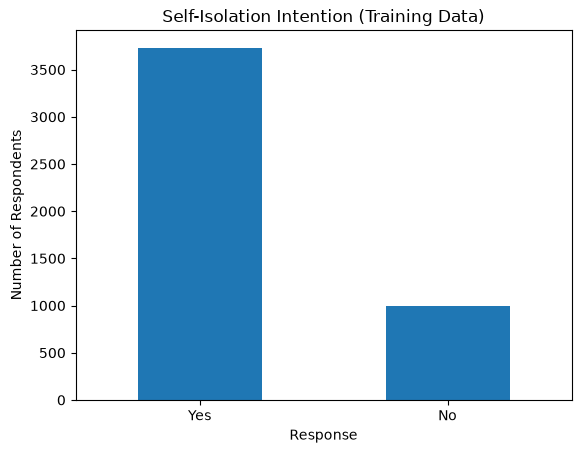

In [10]:
import matplotlib.pyplot as plt

print(train_df["i9_health"].value_counts())

print(train_df["i9_health"].value_counts(normalize=True) * 100)

train_df["i9_health"].value_counts().plot(kind="bar")

plt.title("Self-Isolation Intention (Training Data)")
plt.xlabel("Response")
plt.ylabel("Number of Respondents")
plt.xticks(rotation=0)
plt.show()

### Part 2.2 Region & Target Summary
    Purpose: Sample size Visualization & Self-Isolation Intention by region

In [11]:
region_summary = pd.crosstab(
    train_df["region"],
    train_df["i9_health"]
)

region_summary["Total"] = region_summary.sum(axis=1)
region_summary["No Rate"] = (
    region_summary["No"] / region_summary["Total"] * 100
)

display(region_summary.sort_values("No Rate", ascending=False))

i9_health,No,Yes,Total,No Rate
region,,,,
New Brunswick / Nouveau-Brunswick,27,89,116,23.275862
Quebec / Québec,272,920,1192,22.818792
British Columbia / Colombie Britanique,137,479,616,22.240260
Yukon,2,7,9,22.222222
Ontario,366,1362,1728,21.180556
Manitoba,37,146,183,20.218579
Alberta,101,424,525,19.238095
Newfoundland & Labrador / Terre-Neuve-et-Labrador,11,57,68,16.176471
Nova Scotia / Nouvelle-Écosse,19,100,119,15.966387


### Part 2.3 Categorical variable Vs. Target 
#### Government Performance vs Self-Isolation Intention
    Purpose: Examine whether respondents' evaluations of government pandemic management are associated with self-isolation intention.

i9_health,No,Yes
WCRex1,,
Somewhat badly,0.218530,0.781470
Somewhat well,0.170181,0.829819
Very badly,0.314917,0.685083
Very well,0.159744,0.840256


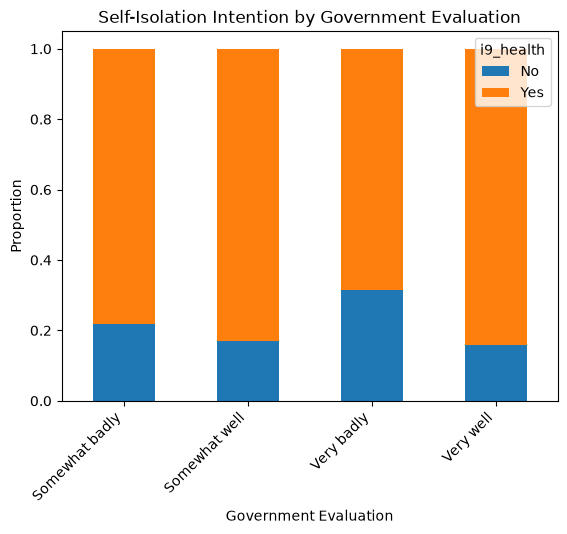

In [12]:
government_pct = pd.crosstab(
    train_df["WCRex1"],
    train_df["i9_health"],
    normalize="index"
)

display(government_pct)

government_pct.plot(kind="bar", stacked=True)

plt.title("Self-Isolation Intention by Government Evaluation")
plt.xlabel("Government Evaluation")
plt.ylabel("Proportion")
plt.xticks(rotation=45, ha="right")
plt.show()

#### Social Contact Avoidance vs Self-Isolation Intention
    Purpose: Examine how recent preventive behavior relates to willingness to self-isolate.

i9_health,No,Yes
Vent_3,,
Always,0.161198,0.838802
Frequently,0.153299,0.846701
Not at all,0.401739,0.598261
Rarely,0.278325,0.721675
Sometimes,0.240000,0.760000


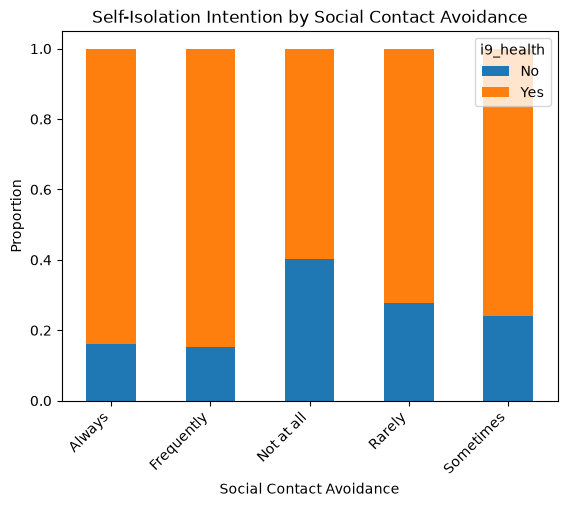

In [13]:
vent_pct = pd.crosstab(
    train_df["Vent_3"],
    train_df["i9_health"],
    normalize="index"
)

display(vent_pct)

vent_pct.plot(kind="bar", stacked=True)

plt.title("Self-Isolation Intention by Social Contact Avoidance")
plt.xlabel("Social Contact Avoidance")
plt.ylabel("Proportion")
plt.xticks(rotation=45, ha="right")
plt.show()

#### Survey Week vs Self-Isolation Intention
    Purpose: Investigate whether self-isolation intentions differ across survey weeks.

qweek
44    482
45    751
46    727
47    674
48    660
49    724
50    711
Name: count, dtype: int64


i9_health,No,Yes
qweek,,
44,0.149378,0.850622
45,0.158455,0.841545
46,0.163686,0.836314
47,0.221068,0.778932
48,0.207576,0.792424
49,0.263812,0.736188
50,0.298172,0.701828


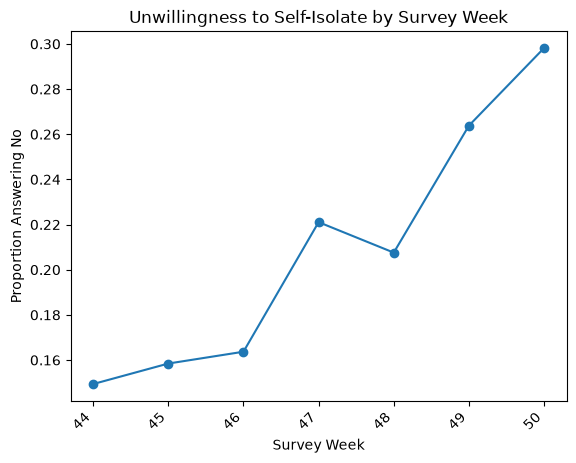

In [14]:
print(train_df["qweek"].value_counts().sort_index())

week_pct = pd.crosstab(
    train_df["qweek"],
    train_df["i9_health"],
    normalize="index"
)

display(week_pct)

week_pct["No"].plot(kind="line", marker="o")

plt.title("Unwillingness to Self-Isolate by Survey Week")
plt.xlabel("Survey Week")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Proportion Answering No")
plt.show()

### Part 2.4 Numeric Distributions
    Purpose: Checking the distribution for numerical variables to find any outliers or skews

               age  cantril_ladder
count  4729.000000     4729.000000
mean     50.228801        6.261155
std      17.973816        2.096472
min      18.000000        0.000000
25%      35.000000        5.000000
50%      51.000000        7.000000
75%      66.000000        8.000000
max      90.000000       10.000000


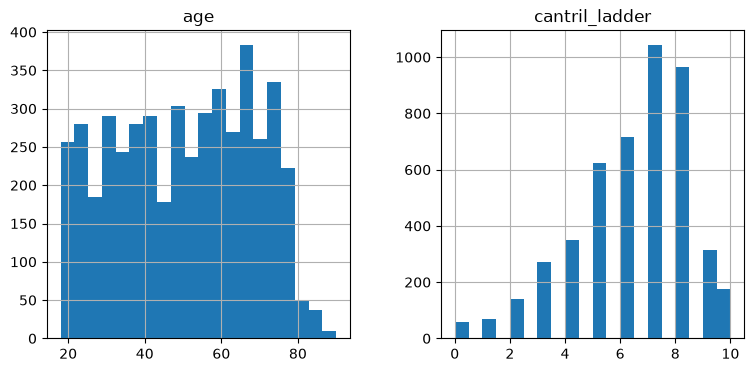

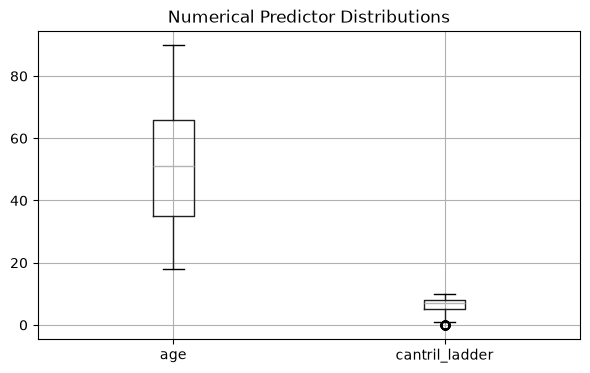

In [15]:
print(train_df[num_cols].describe())

train_df[num_cols].hist(
    bins=20,
    figsize=(9, 4)
)

plt.show()

train_df[num_cols].boxplot(figsize=(7, 4))

plt.title("Numerical Predictor Distributions")
plt.show()

### Part 2.5 Numeric Predictors Vs. Target
    Purpose: Checking if there is diff age distribution within Target variable

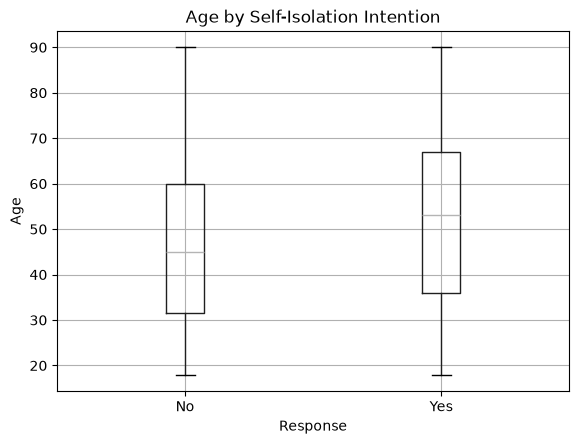

In [16]:
train_df.boxplot(
    column="age",
    by="i9_health"
)

plt.title("Age by Self-Isolation Intention")
plt.suptitle("")
plt.xlabel("Response")
plt.ylabel("Age")
plt.show()

i9_health        No       Yes
age_group                    
18-29      0.258794  0.741206
30-44      0.270370  0.729630
45-59      0.227605  0.772395
60+        0.143263  0.856737


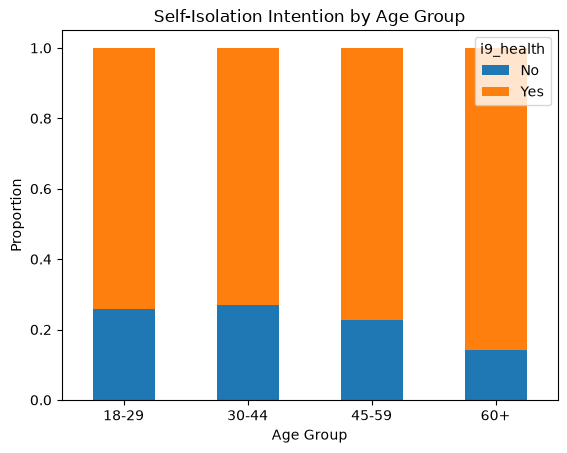

In [17]:
train_df = train_df.copy()

train_df["age_group"] = pd.cut(
    train_df["age"],
    bins=[17, 29, 44, 59, 120],
    labels=["18-29", "30-44", "45-59", "60+"]
)

age_pct = pd.crosstab(
    train_df["age_group"],
    train_df["i9_health"],
    normalize="index"
)

print(age_pct)

age_pct.plot(kind="bar", stacked=True)

plt.title("Self-Isolation Intention by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Proportion")
plt.xticks(rotation=0)
plt.show()

### Part 2.6 Multivariate Analysis
#### Age x Life satisfaction -> No Rate
    Purpose: Investigate the relationship b/w Age & Life Satisfaction after the combination

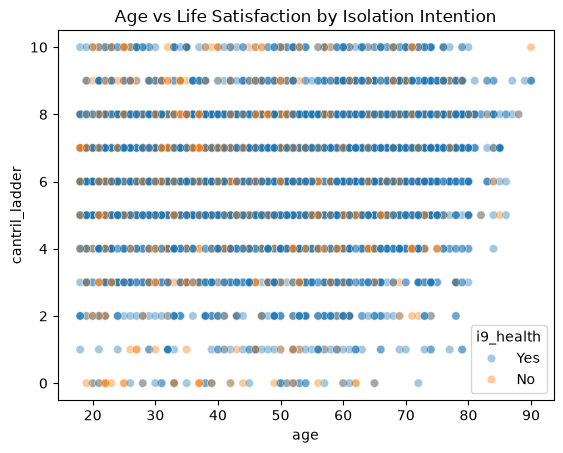

In [18]:
import seaborn as sns

sns.scatterplot(
    data=train_df,
    x="age",
    y="cantril_ladder",
    hue="i9_health",
    alpha=0.4
)

plt.title("Age vs Life Satisfaction by Isolation Intention")
plt.show()

The scatter plot examines the relationship between age, life satisfaction, and self-isolation intention.

There is substantial overlap between respondents who answered "Yes" and "No" across different ages and life satisfaction scores. No clear separation between the two groups is visible.

This suggests that age and life satisfaction alone may not be sufficient to distinguish respondents' self-isolation intentions. However, overlapping points make it difficult to assess the strength of their relationship visually.

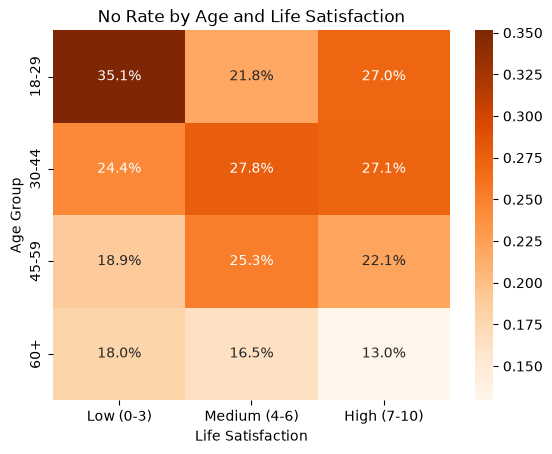

In [19]:
train_df["age_group"] = pd.cut(
    train_df["age"],
    bins=[17, 29, 44, 59, 120],
    labels=["18-29", "30-44", "45-59", "60+"]
)

train_df["satisfaction_group"] = pd.cut(
    train_df["cantril_ladder"],
    bins=[-1, 3, 6, 10],
    labels=["Low (0-3)", "Medium (4-6)", "High (7-10)"]
)

heatmap_data = train_df.pivot_table(
    index="age_group",
    columns="satisfaction_group",
    values="target",
    aggfunc="mean",
    observed=True
)

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1%",
    cmap="Oranges"
)

plt.title("No Rate by Age and Life Satisfaction")
plt.xlabel("Life Satisfaction")
plt.ylabel("Age Group")
plt.show()

#### Government Evaluation × Social Contact Avoidance → No Rate
    Purpose: Explore whether self-isolation intention varies across combinations of government evaluation and preventive behavior.

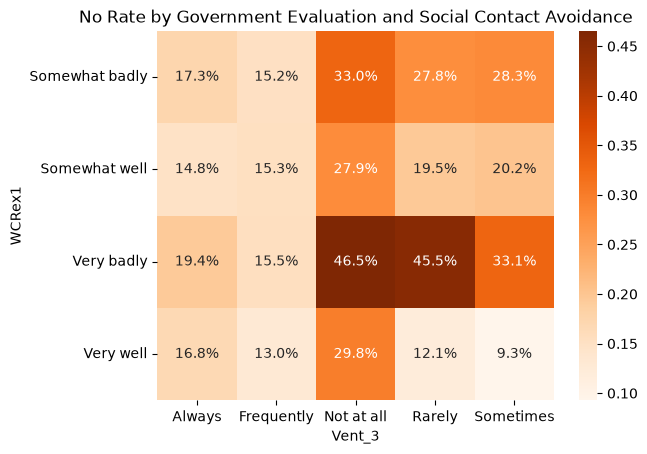

In [20]:
multi = train_df.pivot_table(
    index="WCRex1",
    columns="Vent_3",
    values="target",
    aggfunc="mean"
)

sns.heatmap(
    multi,
    annot=True,
    fmt=".1%",
    cmap="Oranges"
)

plt.title("No Rate by Government Evaluation and Social Contact Avoidance")
plt.show()

In [21]:
pd.crosstab(
    train_df["WCRex1"],
    train_df["Vent_3"]
)

Vent_3,Always,Frequently,Not at all,Rarely,Sometimes
WCRex1,,,,,
Somewhat badly,231,330,112,108,212
Somewhat well,615,803,111,154,356
Very badly,211,187,260,99,148
Very well,298,184,57,33,54


### Part 2.7 Correlation Analysis
    Purpose: Checking any correlation and duplicate information b/w numerical variables

                     age  cantril_ladder
age             1.000000        0.168678
cantril_ladder  0.168678        1.000000


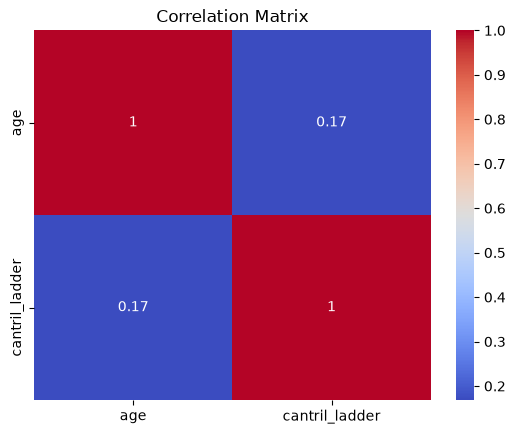

In [22]:
corr = train_df[num_cols].corr()

print(corr)

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Matrix")
plt.show()